Homework 5 - Section 9

Need a way to:

Generate a Synthetic Dataset - sklearn.datasets

Need a way to measure accuracy - sklearn.metrics

It must have an inner circle and outer circle.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

x, y = make_circles(n_samples=400, noise=0.1, factor=0.3, random_state=1)

1.) Plot the data

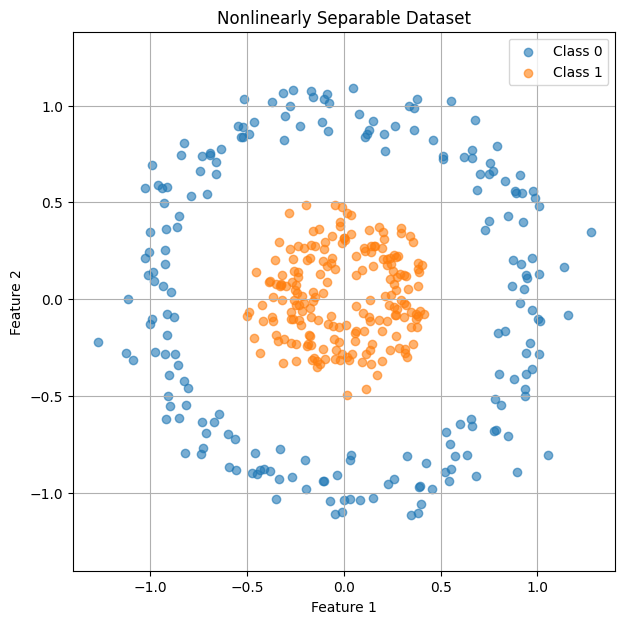

In [2]:
plt.figure(figsize=(7, 7))
plt.scatter(x[y == 0, 0], x[y == 0, 1], label="Class 0", alpha=0.6)
plt.scatter(x[y == 1, 0], x[y == 1, 1], label="Class 1", alpha=0.6)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinearly Separable Dataset")
plt.legend()
plt.axis("equal")
plt.grid()
plt.show()

Linear SVM will fail here because the seperation is nonlinear.

2.) Train the model

In [3]:
svm_linear = SVC(kernel="linear", C=1.0)
svm_linear.fit(x, y)

SVC(kernel='linear')

3.) Calculate the accuracy

In [4]:
y_pred = svm_linear.predict(x)
accuracy = accuracy_score(y, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.6725


4.) Plot the decision boundary

Weights: [0.06099822 1.26711176]
Bias: 0.39407183527477885


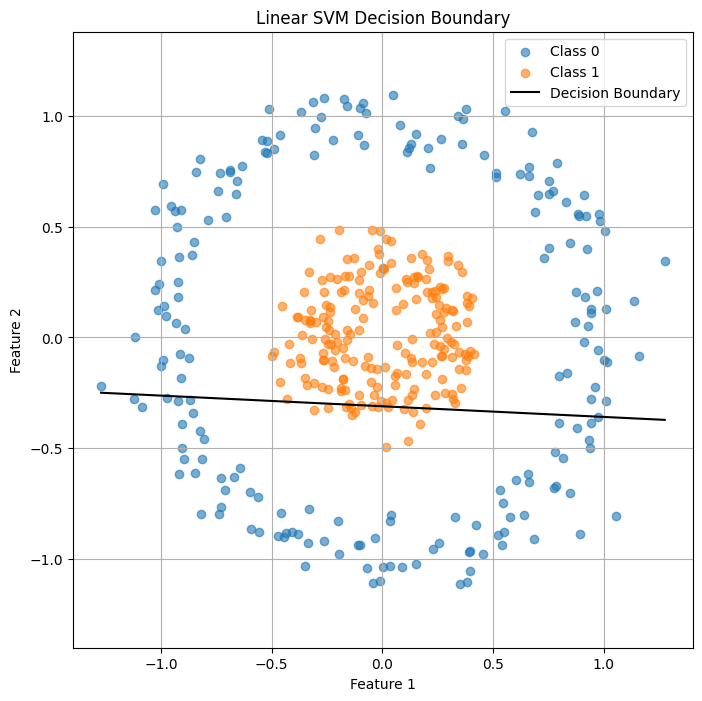

In [5]:
w = svm_linear.coef_[0]
b = svm_linear.intercept_[0]

print("Weights:", w)
print("Bias:", b)

x1 = np.linspace(x[:, 0].min(), x[:, 0].max(), 200)
x2 = -(w[0] * x1 + b) / w[1]

plt.figure(figsize=(8, 8))

plt.scatter(x[y == 0, 0], x[y == 0, 1], label="Class 0", alpha=0.6)

plt.scatter(x[y == 1, 0], x[y == 1, 1], label="Class 1", alpha=0.6)

plt.plot(x1, x2, color="black", label="Decision Boundary")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Linear SVM Decision Boundary")
plt.legend()
plt.axis("equal")
plt.grid()
plt.show()

5.) Implement a nonlinear SVM using the RBF Kernel

In [6]:
# Gamma .1

svm_rbf_gamma = SVC(kernel="rbf", C=1.0, gamma=.1)
svm_rbf_gamma.fit(x, y)

y_pred_rbf_gamma = svm_rbf_gamma.predict(x)
accuracy_rbf_gamma = accuracy_score(y, y_pred_rbf_gamma)
print("RBF Accuracy (Gamma == .1):", accuracy_rbf_gamma)

# Gamma 1

svm_rbf_gamma1 = SVC(kernel="rbf", C=1.0, gamma=1.0)
svm_rbf_gamma1.fit(x, y)

y_pred_rbf_gamma1 = svm_rbf_gamma1.predict(x)
accuracy_rbf_gamma1 = accuracy_score(y, y_pred_rbf_gamma1)
print("RBF Accuracy (Gamma == 1):", accuracy_rbf_gamma1)

# Gamma 10

svm_rbf_gamma10 = SVC(kernel="rbf", C=1.0, gamma=10.0)
svm_rbf_gamma10.fit(x, y)

y_pred_rbf_gamma10 = svm_rbf_gamma10.predict(x)
accuracy_rbf_gamma10 = accuracy_score(y, y_pred_rbf_gamma10)
print("RBF Accuracy (Gamma == 10):", accuracy_rbf_gamma10)

RBF Accuracy (Gamma == .1): 1.0
RBF Accuracy (Gamma == 1): 1.0
RBF Accuracy (Gamma == 10): 1.0


Yeah. It is obvious that the accuracy would be better due to it being able to be nonlinear.

6.) Output this boundary

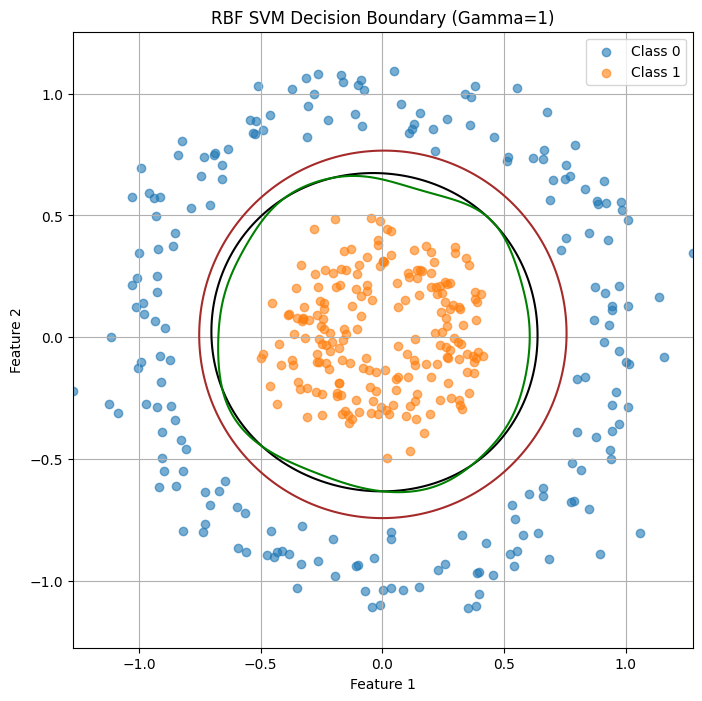

In [7]:
x1_gamma = np.linspace(x[:, 0].min(), x[:, 0].max(), 300)
x2_gamma = np.linspace(x[:, 1].min(), x[:, 1].max(), 300)

x1_gamma1 = np.linspace(x[:, 0].min(), x[:, 0].max(), 300)
x2_gamma1 = np.linspace(x[:, 1].min(), x[:, 1].max(), 300)

x1_gamma10 = np.linspace(x[:, 0].min(), x[:, 0].max(), 300)
x2_gamma10 = np.linspace(x[:, 1].min(), x[:, 1].max(), 300)

xx_gamma, yy_gamma = np.meshgrid(x1_gamma, x2_gamma)
xx_gamma1, yy_gamma1 = np.meshgrid(x1_gamma1, x2_gamma1)
xx_gamma10, yy_gamma10 = np.meshgrid(x1_gamma10, x2_gamma10)

grid_gamma = np.c_[xx_gamma.ravel(), yy_gamma.ravel()]
Z_gamma = svm_rbf_gamma.decision_function(grid_gamma)
Z_gamma = Z_gamma.reshape(xx_gamma.shape)

grid_gamma1 = np.c_[xx_gamma1.ravel(), yy_gamma1.ravel()]
Z_gamma1 = svm_rbf_gamma1.decision_function(grid_gamma1)
Z_gamma1 = Z_gamma1.reshape(xx_gamma1.shape)

grid_gamma10 = np.c_[xx_gamma10.ravel(), yy_gamma10.ravel()]
Z_gamma10 = svm_rbf_gamma10.decision_function(grid_gamma10)
Z_gamma10 = Z_gamma10.reshape(xx_gamma10.shape)

plt.figure(figsize=(8, 8))

plt.scatter(x[y == 0, 0], x[y == 0, 1], label="Class 0", alpha=0.6)
plt.scatter(x[y == 1, 0], x[y == 1, 1], label="Class 1", alpha=0.6)

plt.contour(xx_gamma, yy_gamma, Z_gamma, levels=[0], colors="brown")
plt.contour(xx_gamma1, yy_gamma1, Z_gamma1, levels=[0], colors="black")
plt.contour(xx_gamma10, yy_gamma10, Z_gamma10, levels=[0], colors="green")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("RBF SVM Decision Boundary (Gamma=1)")
plt.legend()
plt.axis("equal")
plt.grid()
plt.show()

As the gamma increases, the model is able to give the decision boundary the ability to exhibit more complex curvature.